# Airbus order tracking vs CSDA STAC

Which Airbus acquisitions in the On-Ramp 2 order tracking sheet (`AirbusTracking` tab) are already in
CSDA STAC, and what is their order status?

| Step | Output |
|---|---|
| 1. Read the tracking sheet | `tracking`: one row per site, Acq #, platform and TOA/SR column, with its status |
| 2. Search CSDA STAC | `res.gdf`: every `airbus-optical` product at the tracked sites (multistac) |
| 2b. Newly arrived tasked acquisitions | fresh search since `TASKING_SINCE` at sites with *New Tasking Submitted* slots, appended to `res` |
| 3. Match | `tracking` gains `acquisition_id`, `in_csda`, `match`, `radiometry_in_csda` |
| 3b. New tasking received | new acquisitions fill the *New Tasking Submitted* slots: `match='new tasking'`, `status='New Tasking Received'` |
| 4. Result | `in_csda_gdf`: GeoDataFrame of the CSDA products of tracked acquisitions + their status |
| 4b. Summary since September | what is new in CSDA STAC since `SINCE` (fresh search, all tracked sites) and how many tasking requests are still waiting: short conclusions and the note for the timeline |

**Status comes from the cell fill colour**, read against the sheet's legend (rows 1-2): Archive Order
Needed / Submitted / Received, Archive to be considered if allocation exists, New Tasking Needed /
Submitted / Received. Black cells are `n/a (black)`; cells with no fill (e.g. most of the SPOT-6 column) are `unmarked`.

**Matching is by platform and acquisition time, at the same site.** The sheet gives PHR/SPOT as datastrip
IDs (`DS_PHR1A_202304050917383_...`, time to 0.1 s) and PNeo as a date + `ACQ_` ID; CSDA item IDs start with
the platform and time (`PNEO4_202305100917387_PAN_ORT_RFL`). PHR matches to the 0.1 s; PNeo dates are
within ~1-3 s of the CSDA ID. A match within `MATCH_SECONDS` is `match='id time'`; within `PASS_SECONDS`
it is `'same pass?'` (e.g. SPOT-6 datastrip start vs. scene time, ~17 s): check those.

Library: `lib/order_tracking.py` (sheet reader), `lib/multistac.py` (search).

In [1]:
import sys
sys.path.append('/home/pmontesa/code/csda_summaries/lib')

import importlib
import pandas as pd
import geopandas as gpd
import multistac, multistac_plots, order_tracking
for m in (multistac, multistac_plots, order_tracking):
    importlib.reload(m)

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 200)
pd.set_option('display.max_rows', 200)

## Parameters

In [2]:
TRACKING_XLSX = '/home/pmontesa/code/csda_summaries/sites/OnRamp2_OrderTracking_August2026.xlsx'
TRACKING_SHEET = 'AirbusTracking'
SITES = '/home/pmontesa/code/csda_summaries/sites/csda_sites_aoi.geojson'
SITE_NAME_FIELD = 'Site Name'
SITE_ALIASES = {'Libya 4': 'PICS Libya-4'}   # tracking-sheet name -> name in the sites file

START, END = '2012-01-01', pd.Timestamp.today().strftime('%Y-%m-%d')   # Pleiades 1A launched Dec 2011
PROVIDERS = {'csda': ['airbus-optical']}

MATCH_SECONDS = 5     # CSDA acquisition within this of the sheet's time = the same acquisition
PASS_SECONDS = 120    # within this = probably the same pass (flagged 'same pass?' to check)

TASKING_SINCE = '2026-08-01'                 # new tasking submitted (On-Ramp 2, Aug 2026): later CSDA acquisitions can fill its slots
NEW_TASKING_STATUS = 'New Tasking Submitted'  # sheet status of the slots waiting for a tasked acquisition
SINCE = '2026-09-01'                         # section 4b summary: images acquired on or after this date

CACHE_DIR = '/explore/nobackup/people/pmontesa/stac_cache/multistac'
OUT_DIR = '/explore/nobackup/people/pmontesa/multistac/airbus_order_tracking'

## 1. The tracking sheet as a dataframe

One row per filled cell: `acq_time` comes from the DS_ ID (PHR, SPOT) or the PNeo date column. Empty cells
that carry a status (e.g. a *New Tasking Submitted* slot with no acquisition yet) are kept with no `tracking_id`.

In [3]:
tracking = order_tracking.read_airbus_tracking(TRACKING_XLSX, TRACKING_SHEET, site_aliases=SITE_ALIASES)
print(f"{len(tracking)} tracked cells, {tracking.tracking_id.notna().sum()} with an ID, "
      f"{tracking.acq_time.notna().sum()} with an acquisition time")
tracking.head(10)

281 tracked cells, 179 with an ID, 170 with an acquisition time


,site_name,acq_num,platform,radiometry,status,tracking_id,acq_time,sheet_note,cell,cells
0,Gobabeb,1,PHR1A,TOA,Archive Order Submitted,DS_PHR1A_202304050917383_FR1_PX_E015S24_0110_0...,2023-04-05 09:17:38.300000+00:00,CSDA has 3 scenes,C6,C6
1,Gobabeb,1,PHR1B,TOA,Archive Order Submitted,DS_PHR1B_202508160921429_FR1_PX_E015S24_0210_0...,2025-08-16 09:21:42.900000+00:00,CSDA has 3 scenes,E6,E6
2,Gobabeb,1,PNEO3,TOA,Archive Order Submitted,ACQ_PNEO3_02908906927283,2023-05-02 09:13:59.581000+00:00,CSDA has 3 scenes,G6,G6 H6
3,Gobabeb,1,PNEO4,TOA,Archive Order Submitted,ACQ_PNEO4_02901507036755,2023-05-10 09:17:38.338000+00:00,CSDA has 3 scenes,J6,J6 K6
4,Gobabeb,1,SPOT6,TOA,unmarked,DS_SPOT6_202305020844290_FR1_FR1_FR1_FR1_E015S...,2023-05-02 08:44:29+00:00,None,M6,M6
5,Gobabeb,2,PHR1A,TOA,Archive Order Submitted,DS_PHR1A_202604270917524_FR1_PX_E015S24_0110_0...,2026-04-27 09:17:52.400000+00:00,CSDA has 3 scenes,C7,C7
6,Gobabeb,2,PNEO3,TOA,Archive Order Submitted,ACQ_PNEO3_03208908006809,2023-07-19 09:14:16.459000+00:00,CSDA has 3 scenes,G7,G7 H7
7,Gobabeb,2,PNEO4,TOA,Archive Order Submitted,ACQ_PNEO4_03008907468219,2023-06-10 09:14:11.706000+00:00,CSDA has 3 scenes,J7,J7 K7
8,Gobabeb,2,SPOT6,TOA,unmarked,DS_SPOT6_202309090844195_FR1_FR1_FR1_FR1_E015S...,2023-09-09 08:44:19.500000+00:00,None,M7,M7
9,Gobabeb,3,PHR1A,TOA,Archive to be considered if allocation exists,DS_PHR1A_202404030917218_FR1_PX_E015S24_0110_0...,2024-04-03 09:17:21.800000+00:00,CSDA has 3 scenes,C8,C8


In [4]:
# Status of every tracked cell, by platform and TOA/SR column
tracking.groupby(['platform', 'radiometry', 'status']).size().unstack(['platform', 'radiometry'], fill_value=0)

platform                                      PHR1A     PHR1B     PNEO3     PNEO4     SPOT6    
radiometry                                       SR TOA    SR TOA    SR TOA    SR TOA    SR TOA
status                                                                                         
Archive Order Needed                              0   0     0   1     0   0     0   0     0   0
Archive Order Submitted                           0  16     0  14     1  18     3  20     0   0
Archive to be considered if allocation exists     0   8     0   6     0   0     0   0     0   0
New Tasking Needed                                0   0     0   0     0   0     0   0     4   5
New Tasking Submitted                             0  10     0  13    15  21    13  21     0   0
n/a (black)                                       8   0     3   0     1   0     8   0     8   0
unmarked                                          0   0     0   0     0   0     0   0    14  50

## 2. Search CSDA STAC at the tracked sites

In [5]:
sites = multistac.load_sites(SITES, site_name_field=SITE_NAME_FIELD)
sites = sites[sites.site_name.isin(tracking.site_name.unique())]
missing = sorted(set(tracking.site_name) - set(sites.site_name))
if missing:
    print('Tracking sites not in the sites file (add to SITE_ALIASES):', missing)
print(len(sites), 'sites:', ', '.join(sites.site_name))

8 sites: Baotou, Gobabeb, La Crau, PICS Libya-4, Railroad Valley, Valencia, WLEF, Golmud


In [6]:
%%time
res = multistac.search(sites, START, END, PROVIDERS, cache_dir=CACHE_DIR)
print(res)
res.log[res.log.status == 'failed']

searches: 100%|██████████| 8/8 [00:00<00:00, 83886.08it/s]

SearchResult(492 rows, 492 unique items, 0 failed tasks)
CPU times: user 209 ms, sys: 38 ms, total: 247 ms
Wall time: 866 ms


,provider,collection,site_name,interval,status,count,matched,server_filters,error,seconds


## 2b. Search CSDA STAC for newly arrived tasked acquisitions

The *New Tasking Submitted* slots in the sheet have no ID or time yet, so they cannot be matched like the archive
acquisitions. Search the sites that have such slots from `TASKING_SINCE` to today, **without the cache** (so products
delivered since the last run are found), and append the results to `res`. Section 3b assigns them to the slots.

In [7]:
tasked_sites = sites[sites.site_name.isin(tracking.loc[tracking.status == NEW_TASKING_STATUS, 'site_name'])]
res_new = multistac.search(tasked_sites, TASKING_SINCE, END, PROVIDERS)   # no cache_dir: always a fresh search
print(res_new, '|', ', '.join(tasked_sites.site_name))

# Append to the tracked-site search; the dates overlap, so keep one row per product and site
res = multistac.SearchResult(
    pd.concat([res.gdf, res_new.gdf], ignore_index=True).drop_duplicates(['id', 'site_name'], ignore_index=True),
    list({item['id']: item for item in res.items + res_new.items}.values()),
    pd.concat([res.log, res_new.log], ignore_index=True))
print('combined:', res)
res_new.gdf.groupby(['site_name', 'sensor']).acquisition_id.nunique().unstack(fill_value=0)

searches: 100%|██████████| 4/4 [00:00<00:00,  7.11it/s]


SearchResult(50 rows, 50 unique items, 0 failed tasks) | Baotou, Valencia, WLEF, Golmud
combined: SearchResult(492 rows, 492 unique items, 0 failed tasks)


sensor,PHR1A,PHR1B,PNEO3,PNEO4
site_name,,,,
Baotou,2,2,3,2
Golmud,0,0,1,1
Valencia,0,0,1,0
WLEF,1,1,4,1


sensor,PHR1A,PHR1B,PNEO3,PNEO4
site_name,,,,
Baotou,2,2,3,2
Golmud,0,0,1,1
Valencia,0,0,1,0
WLEF,1,1,4,1


In [8]:
from datetime import date

today = date.today()

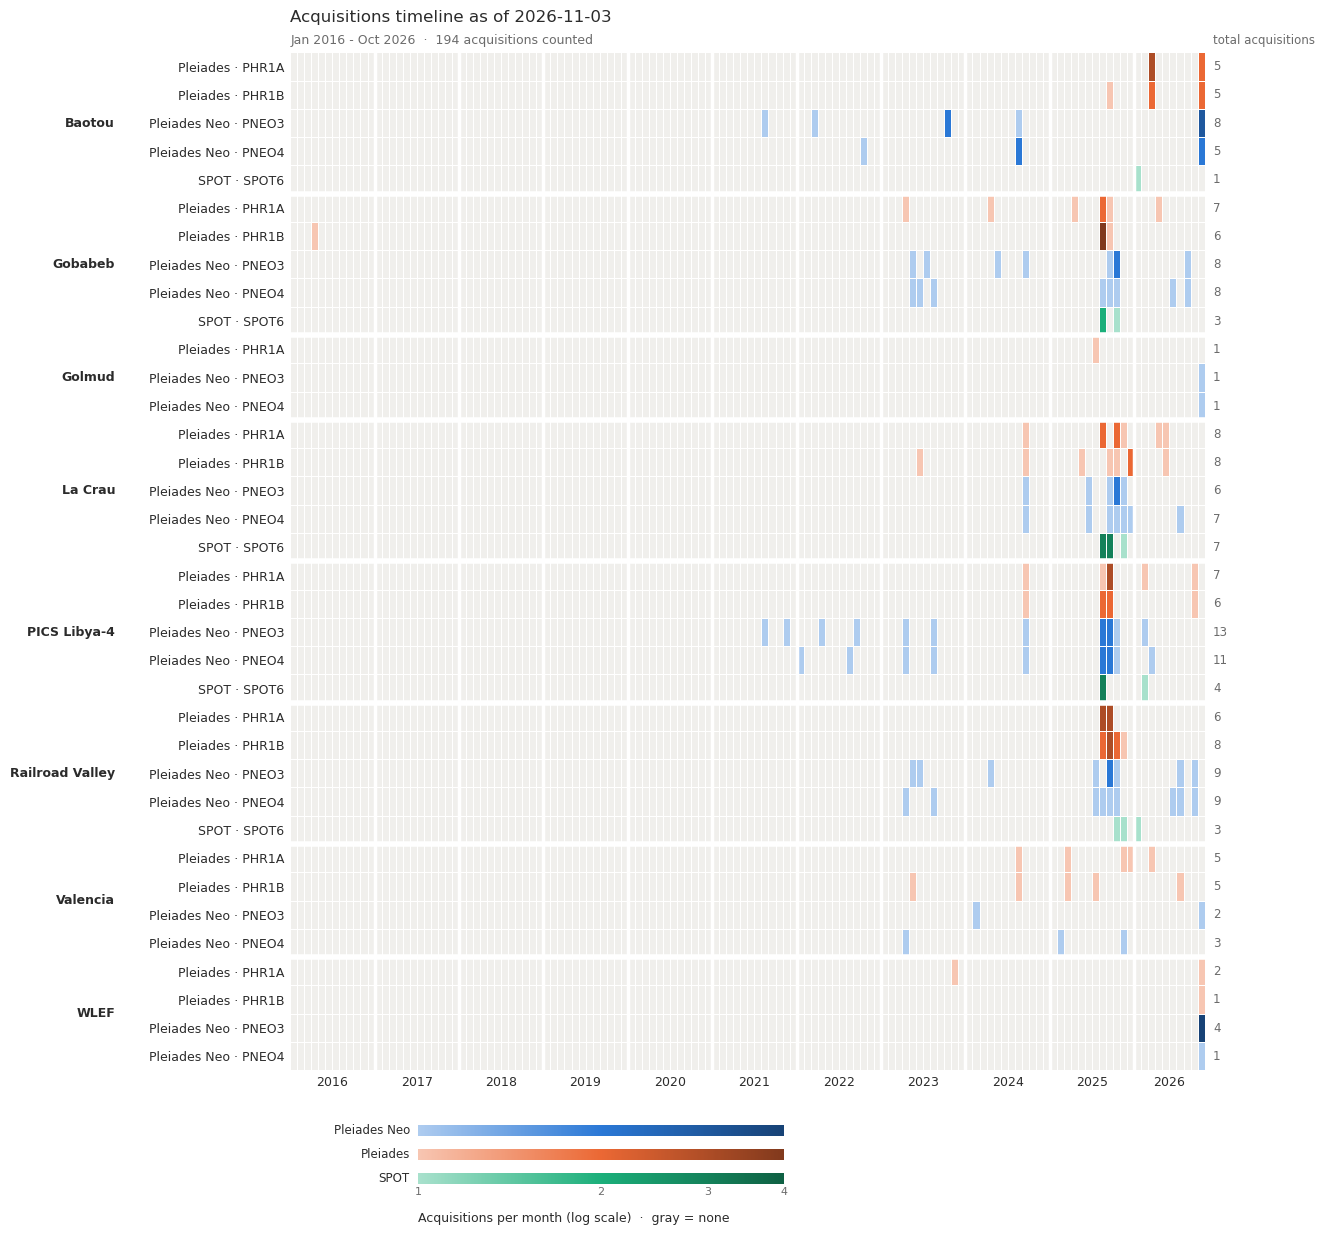

In [9]:
# Acquisitions: how often each site group was imaged (products of one collect counted once)
multistac_plots.plot_month_heatmap(res.by_month(['site_name','constellation','sensor'], count='acquisitions'), color_by='constellation', max_rows=None,
                                   title=f'Acquisitions timeline as of {today}');

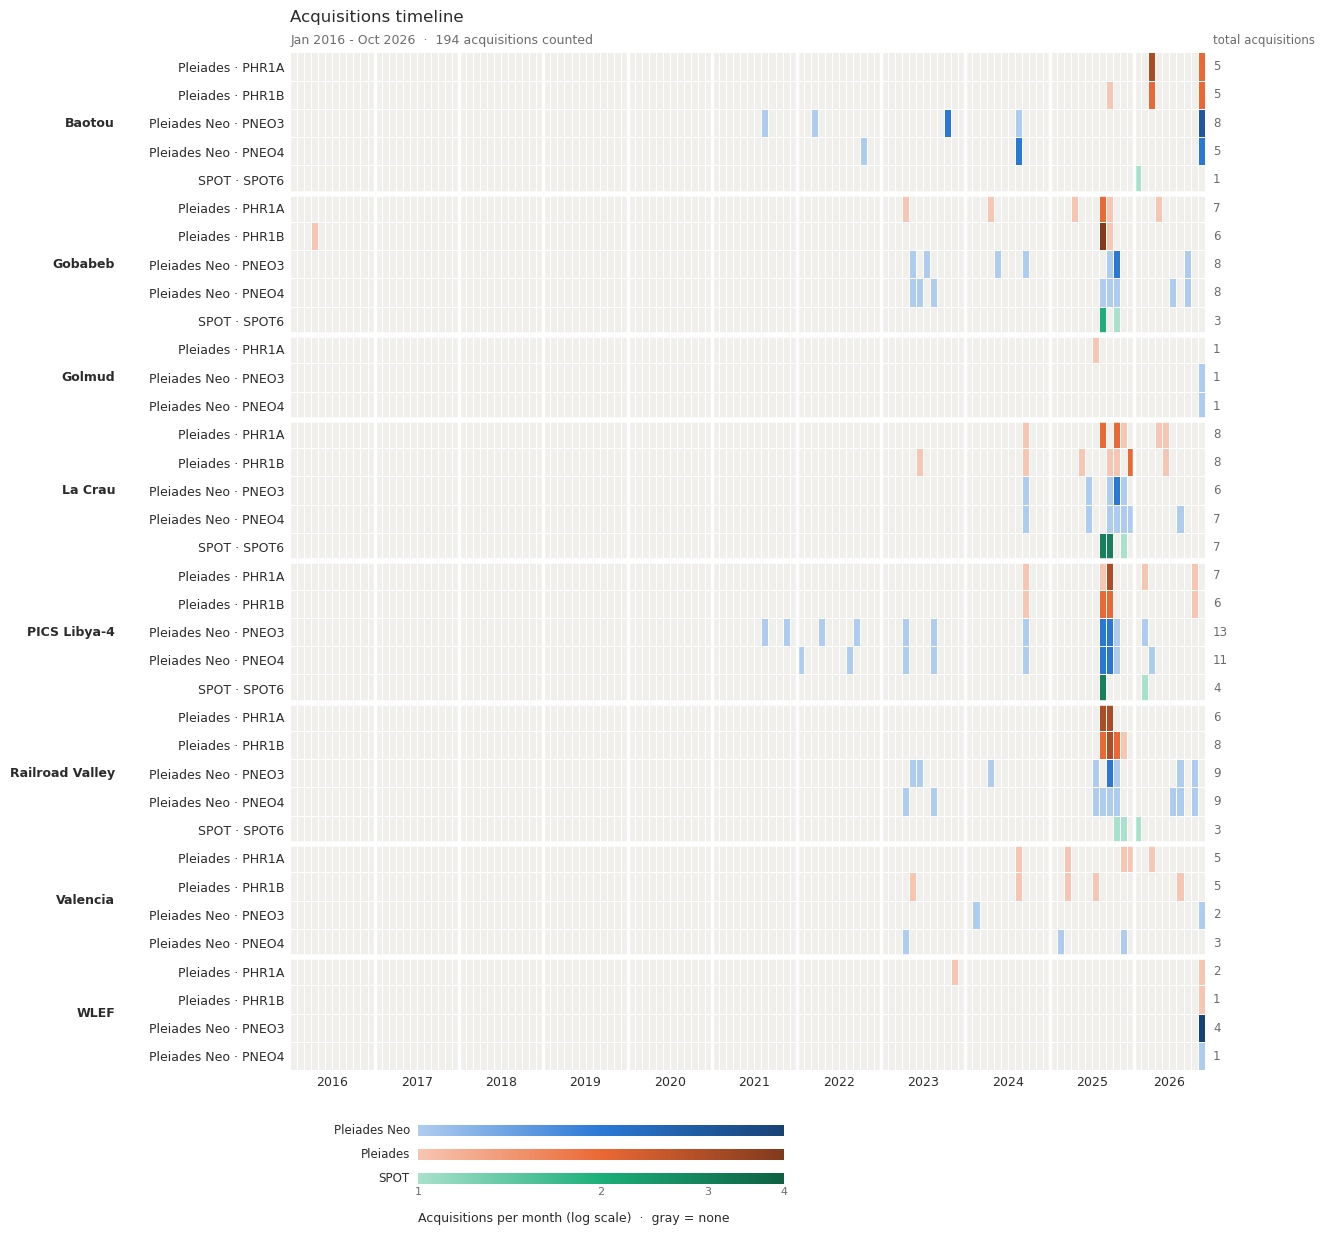

In [10]:
# Acquisitions: how often each site group was imaged (products of one collect counted once)
multistac_plots.plot_month_heatmap(res.by_month(['site_name','constellation','sensor'], count='acquisitions'), color_by='constellation', max_rows=None,
                                   title='Acquisitions timeline');

In [11]:
# Platform, acquisition time and radiometry of each CSDA product (time from the item ID, as in the sheet)
csda = res.gdf.copy()
parsed = csda['id'].map(order_tracking.id_time)
csda['platform_id'] = [p for p, t in parsed]
csda['acq_time'] = [t for p, t in parsed]
csda['radiometry'] = (csda['airbus-optical:radiometric_processing']
                      .map({'REFLECTANCE': 'TOA', 'SURFACE_REFLECTANCE': 'SR', 'BASIC': 'basic'})
                      .fillna(csda['airbus-optical:radiometric_processing']))

# One row per CSDA acquisition and site
csda_acqs = (csda.dropna(subset=['acq_time'])
             .groupby(['site_name', 'platform_id', 'acquisition_id'], as_index=False)
             .agg(csda_time=('acq_time', 'first'), n_products=('id', 'nunique'),
                  csda_radiometry=('radiometry', lambda s: ', '.join(sorted(s.dropna().unique())))))
csda_acqs.groupby(['site_name', 'platform_id']).size().unstack(fill_value=0)

platform_id,PHR1A,PHR1B,PNEO3,PNEO4,SPOT6
site_name,,,,,
Baotou,5,5,8,5,1
Gobabeb,7,6,8,8,3
Golmud,1,0,1,1,0
La Crau,8,8,6,7,7
PICS Libya-4,7,6,13,11,4
Railroad Valley,6,8,9,9,3
Valencia,5,5,2,3,0
WLEF,2,1,4,1,0


## 3. Match the sheet to CSDA

Nearest CSDA acquisition of the same platform at the same site, within `PASS_SECONDS`.
`radiometry_in_csda` says whether CSDA has the sheet column's radiometry (TOA = `REFLECTANCE`, SR = `SURFACE_REFLECTANCE`).

In [12]:
timed = tracking.dropna(subset=['acq_time']).reset_index().sort_values('acq_time')
nearest = pd.merge_asof(timed, csda_acqs.rename(columns={'platform_id': 'platform'}).sort_values('csda_time'),
                        left_on='acq_time', right_on='csda_time', by=['site_name', 'platform'],
                        tolerance=pd.Timedelta(seconds=PASS_SECONDS), direction='nearest').set_index('index')

tracking = tracking.join(nearest[['acquisition_id', 'csda_time', 'n_products', 'csda_radiometry']])
tracking['dt_seconds'] = (tracking.csda_time - tracking.acq_time).dt.total_seconds().round(1)
tracking['in_csda'] = tracking.acquisition_id.notna()
tracking['match'] = None
tracking.loc[tracking.in_csda, 'match'] = 'same pass?'
tracking.loc[tracking.dt_seconds.abs() <= MATCH_SECONDS, 'match'] = 'id time'
tracking['radiometry_in_csda'] = [bool(r in str(c).split(', ')) if i else False
                                  for r, c, i in zip(tracking.radiometry, tracking.csda_radiometry, tracking.in_csda)]

print(tracking.match.value_counts(dropna=False).to_dict())
tracking[tracking.match == 'same pass?'][['site_name', 'acq_num', 'platform', 'tracking_id', 'acquisition_id', 'dt_seconds']]

{None: 183, 'id time': 90, 'same pass?': 8}


,site_name,acq_num,platform,tracking_id,acquisition_id,dt_seconds
23,Gobabeb,8,SPOT6,DS_SPOT6_202508300847449_FR1_FR1_FR1_FR1_E015S...,SPOT6_202508300847275,-17.4
96,Railroad Valley,5,SPOT6,DS_SPOT6_202510231807029_FR1_FR1_FR1_FR1_W116N...,SPOT6_202510231807202,17.3
106,Valencia,1,PNEO3,ACQ_PNEO3_04010510548277,PNEO3_202402131053274,7.6
107,Valencia,1,PNEO3,ACQ_PNEO3_04010510548277,PNEO3_202402131053274,7.6
108,Valencia,1,PNEO4,ACQ_PNEO4_02817906831442,PNEO4_202304251049260,9.9
109,Valencia,1,PNEO4,ACQ_PNEO4_02817906831442,PNEO4_202304251049260,9.9
117,Valencia,2,PNEO4,ACQ_PNEO4_05317915422180,PNEO4_202502031049133,8.1
118,Valencia,2,PNEO4,ACQ_PNEO4_05317915422180,PNEO4_202502031049133,8.1


## 3b. New tasking received

Newly tasked acquisitions are not in the sheet yet, so they are matched to **slots**, not by time: CSDA acquisitions at
a site with *New Tasking Submitted* slots, of a platform that has a slot there, acquired on or after `TASKING_SINCE`,
and not matched to an archive cell in section 3. They fill that site and platform's slots in Acq # order, oldest
first. A TOA or SR slot is filled only if CSDA has that radiometry. Deliveries beyond the free slots are listed, not written.

Filled slots get `match='new tasking'`, `status='New Tasking Received'` (what section 5 writes to the sheet) and
`acq_time` = the CSDA acquisition time. Run from section 3 again before re-running this cell.

In [13]:
assert not tracking.match.eq('new tasking').any(), 'New tasking already assigned: re-run from section 3 first'
slots = tracking[tracking.status == NEW_TASKING_STATUS]
archive_ids = set(tracking.loc[tracking.in_csda, 'acquisition_id'])

arrived = csda_acqs.rename(columns={'platform_id': 'platform'})
arrived = arrived[(arrived.csda_time >= pd.Timestamp(TASKING_SINCE, tz='UTC')) & ~arrived.acquisition_id.isin(archive_ids)]
arrived = arrived.merge(slots[['site_name', 'platform']].drop_duplicates()).sort_values('csda_time')

# k-th new acquisition of a site and platform -> its k-th slot row (Acq #)
arrived['k'] = arrived.groupby(['site_name', 'platform']).cumcount()
slot_rows = (slots[['site_name', 'platform', 'acq_num']].drop_duplicates().sort_values('acq_num')
             .assign(k=lambda d: d.groupby(['site_name', 'platform']).cumcount()))
arrived = arrived.merge(slot_rows, on=['site_name', 'platform', 'k'], how='left')
no_slot = arrived[arrived.acq_num.isna()]

filled = slots[['site_name', 'acq_num', 'platform', 'radiometry']].reset_index().merge(
    arrived.dropna(subset=['acq_num']).astype({'acq_num': int}), on=['site_name', 'platform', 'acq_num'])
filled = filled[[r in c.split(', ') for r, c in zip(filled.radiometry, filled.csda_radiometry)]].set_index('index')

for col in ('acquisition_id', 'csda_time', 'n_products', 'csda_radiometry'):
    tracking.loc[filled.index, col] = filled[col]
tracking.loc[filled.index, 'acq_time'] = filled.csda_time
tracking.loc[filled.index, 'dt_seconds'] = 0.0
tracking.loc[filled.index, 'in_csda'] = True
tracking.loc[filled.index, 'radiometry_in_csda'] = True
tracking.loc[filled.index, 'match'] = 'new tasking'
tracking.loc[filled.index, 'status'] = 'New Tasking Received'

print(f"{arrived.acquisition_id.nunique()} newly arrived acquisitions at tasked sites since {TASKING_SINCE}: "
      f"{len(filled)} slots filled, {len(no_slot)} acquisitions with no free slot, "
      f"{(tracking.status == NEW_TASKING_STATUS).sum()} slots still waiting")
tracking.loc[filled.index, ['site_name', 'acq_num', 'platform', 'radiometry', 'acquisition_id', 'acq_time',
                            'csda_radiometry', 'cells']].sort_values(['site_name', 'platform', 'acq_num', 'radiometry'])

19 newly arrived acquisitions at tasked sites since 2026-08-01: 24 slots filled, 1 acquisitions with no free slot, 69 slots still waiting


,site_name,acq_num,platform,radiometry,acquisition_id,acq_time,csda_radiometry,cells
index,,,,,,,,
259,Baotou,4,PHR1A,TOA,PHR1A_202610230337375,2026-10-23 03:37:37.500000+00:00,TOA,C66
266,Baotou,5,PHR1A,TOA,PHR1A_202610300333504,2026-10-30 03:33:50.400000+00:00,TOA,C67
253,Baotou,3,PHR1B,TOA,PHR1B_202610220344313,2026-10-22 03:44:31.300000+00:00,TOA,E65
260,Baotou,4,PHR1B,TOA,PHR1B_202610290340226,2026-10-29 03:40:22.600000+00:00,TOA,E66
254,Baotou,3,PNEO3,TOA,PNEO3_202610100338368,2026-10-10 03:38:36.800000+00:00,TOA,G65 H65
261,Baotou,4,PNEO3,TOA,PNEO3_202610150335108,2026-10-15 03:35:10.800000+00:00,TOA,G66 H66
248,Baotou,2,PNEO4,TOA,PNEO4_202610180342112,2026-10-18 03:42:11.200000+00:00,TOA,J64 K64
255,Baotou,3,PNEO4,TOA,PNEO4_202610230338218,2026-10-23 03:38:21.800000+00:00,TOA,J65 K65
31,Golmud,2,PNEO3,TOA,PNEO3_202610130435470,2026-10-13 04:35:47+00:00,TOA,G16 H16


In [14]:
# Newly arrived acquisitions with no free slot (not written to the sheet; still listed here)
no_slot[['site_name', 'platform', 'acquisition_id', 'csda_time', 'n_products', 'csda_radiometry']]

,site_name,platform,acquisition_id,csda_time,n_products,csda_radiometry
16,Baotou,PNEO3,PNEO3_202610260345575,2026-10-26 03:45:57.500000+00:00,2,TOA


In [15]:
# Tracked cells with an acquisition: how many are in CSDA, by status
has_acq = tracking[tracking.acq_time.notna()]
(has_acq.groupby(['status', 'platform'])
        .agg(tracked=('cell', 'size'), in_csda=('in_csda', 'sum'), radiometry_in_csda=('radiometry_in_csda', 'sum'))
        .unstack('platform', fill_value=0))

tracked                         in_csda                         radiometry_in_csda                        
platform                                        PHR1A PHR1B PNEO3 PNEO4 SPOT6   PHR1A PHR1B PNEO3 PNEO4 SPOT6              PHR1A PHR1B PNEO3 PNEO4 SPOT6
status                                                                                                                                                  
Archive Order Needed                                0     1     0     0     0       0     1     0     0     0                  0     1     0     0     0
Archive Order Submitted                            16    14    19    23     0      16    14    18    22     0                 16    14    18    22     0
Archive to be considered if allocation exists       8     6     0     0     0       8     6     0     0     0                  8     6     0     0     0
New Tasking Received                                3     3    13     5     0       3     3    13     5     0                  3     3    13     5     0
n/a (black)                                         8     3     0     0     8       8     3     0     0     0                  0     0     0     0     0
unmarked                                            0     0     0     0    64       0     0     0     0     2                  0     0     0     0     2

In [16]:
# Cells the matching cannot use: an ID with no acquisition time (e.g. PNeo SR ACQ_ IDs unlike the TOA one, ACQ_CP_...)
tracking[tracking.tracking_id.notna() & tracking.acq_time.isna()][['site_name', 'acq_num', 'platform', 'radiometry', 'status', 'tracking_id', 'cell']]

,site_name,acq_num,platform,radiometry,status,tracking_id,cell
239,Baotou,1,PNEO3,SR,n/a (black),ACQ_PNEO3_03507108827978,I63
241,Baotou,1,PNEO4,SR,n/a (black),ACQ_PNEO4_03338208578483,L63
249,Baotou,2,PNEO4,SR,n/a (black),ACQ_CP_PNEO4_033382_0000604612_ST_0-41,L64
256,Baotou,3,PNEO4,SR,n/a (black),ACQ_CP_PNEO4_033382_0000604612_TS_0-67,L65
263,Baotou,4,PNEO4,SR,n/a (black),ACQ_CP_PNEO4_033382_0000604612_ST_0-67,L66
269,Baotou,5,PNEO4,SR,n/a (black),ACQ_PNEO4_03338208578484,L67
272,Baotou,6,PNEO4,SR,n/a (black),ACQ_CP_PNEO4_033382_0000604612_ST_0-27,L68
275,Baotou,7,PNEO4,SR,n/a (black),ACQ_PNEO4_03338208578485,L69
278,Baotou,8,PNEO4,SR,n/a (black),ACQ_PNEO4_04529312673729,L70


## 4. Result: tracked acquisitions already in CSDA STAC

`in_csda_gdf`: one row per CSDA product (and site) of a tracked acquisition, with the sheet's status for the
TOA and SR columns (`status_TOA`, `status_SR`) and `status` = the status of the column matching this product's
radiometry (none for `basic` products).

In [17]:
in_sheet = tracking[tracking.in_csda]
per_acq = (in_sheet.pivot_table(index=['site_name', 'platform', 'acquisition_id'], columns='radiometry',
                                values=['status', 'tracking_id', 'cell'], aggfunc='first'))
per_acq.columns = [f'{v}_{r}' for v, r in per_acq.columns]
per_acq = per_acq.join(in_sheet.groupby(['site_name', 'platform', 'acquisition_id'])
                       .agg(acq_num=('acq_num', 'first'), sheet_time=('acq_time', 'first'),
                            dt_seconds=('dt_seconds', 'first'), match=('match', 'first'))).reset_index()

in_csda_gdf = csda.rename(columns={'platform_id': 'sheet_platform'}).merge(
    per_acq.rename(columns={'platform': 'sheet_platform'}), on=['site_name', 'sheet_platform', 'acquisition_id'])
in_csda_gdf['status'] = [row.get(f'status_{r}') if r in ('TOA', 'SR') else None
                         for r, (_, row) in zip(in_csda_gdf.radiometry, in_csda_gdf.iterrows())]
cols = ['site_name', 'acq_num', 'sheet_platform', 'acquisition_id', 'id', 'datetime', 'radiometry', 'spectral_mode',
        'status', 'status_TOA', 'status_SR', 'tracking_id_TOA', 'tracking_id_SR', 'match', 'dt_seconds',
        'cloud_cover', 'off_nadir', 'gsd', 'cell_TOA', 'cell_SR', 'stac_self_href', 'geometry']
in_csda_gdf = gpd.GeoDataFrame(in_csda_gdf[[c for c in cols if c in in_csda_gdf]], geometry='geometry', crs=csda.crs) \
    .sort_values(['site_name', 'sheet_platform', 'datetime', 'id']).reset_index(drop=True)
print(f"{in_csda_gdf.acquisition_id.nunique()} tracked acquisitions in CSDA "
      f"({len(in_csda_gdf)} products) at {in_csda_gdf.site_name.nunique()} sites")
in_csda_gdf.drop(columns='geometry').head(20)

101 tracked acquisitions in CSDA (222 products) at 8 sites


,site_name,acq_num,sheet_platform,acquisition_id,id,datetime,radiometry,spectral_mode,status,status_TOA,status_SR,tracking_id_TOA,tracking_id_SR,match,dt_seconds,cloud_cover,off_nadir,gsd,cell_TOA,cell_SR,stac_self_href
0,Baotou,1,PHR1A,PHR1A_202603080348159,PHR1A_202603080348159_MS_ORT_RFL,2026-03-08 03:48:15.900000+00:00,TOA,ms,Archive Order Submitted,Archive Order Submitted,n/a (black),DS_PHR1A_202603080348159_FR1_PX_E109N40_0821_0...,DS_PHR1A_202603080348159_FR1_PX_E109N40_0821_0...,id time,0.0,0.00,13.273512,2.0,C63,D63,https://csdap.earthdata.nasa.gov/stac/collecti...
1,Baotou,1,PHR1A,PHR1A_202603080348159,PHR1A_202603080348159_P_ORT_RFL,2026-03-08 03:48:15.900000+00:00,TOA,pan,Archive Order Submitted,Archive Order Submitted,n/a (black),DS_PHR1A_202603080348159_FR1_PX_E109N40_0821_0...,DS_PHR1A_202603080348159_FR1_PX_E109N40_0821_0...,id time,0.0,0.00,13.273512,0.5,C63,D63,https://csdap.earthdata.nasa.gov/stac/collecti...
2,Baotou,2,PHR1A,PHR1A_202603100333151,PHR1A_202603100333151_MS_ORT_RFL,2026-03-10 03:33:15.100000+00:00,TOA,ms,Archive Order Submitted,Archive Order Submitted,NaN,DS_PHR1A_202603100333151_FR1_PX_E109N40_0821_0...,NaN,id time,0.0,0.00,13.547493,2.0,C64,NaN,https://csdap.earthdata.nasa.gov/stac/collecti...
3,Baotou,2,PHR1A,PHR1A_202603100333151,PHR1A_202603100333151_P_ORT_RFL,2026-03-10 03:33:15.100000+00:00,TOA,pan,Archive Order Submitted,Archive Order Submitted,NaN,DS_PHR1A_202603100333151_FR1_PX_E109N40_0821_0...,NaN,id time,0.0,0.00,13.547493,0.5,C64,NaN,https://csdap.earthdata.nasa.gov/stac/collecti...
4,Baotou,3,PHR1A,PHR1A_202603150344363,PHR1A_202603150344363_MS_ORT_RFL,2026-03-15 03:44:36.300000+00:00,TOA,ms,Archive Order Submitted,Archive Order Submitted,NaN,DS_PHR1A_202603150344363_FR1_PX_E109N40_0821_0...,NaN,id time,0.0,0.00,8.087036,2.0,C65,NaN,https://csdap.earthdata.nasa.gov/stac/collecti...
5,Baotou,3,PHR1A,PHR1A_202603150344363,PHR1A_202603150344363_P_ORT_RFL,2026-03-15 03:44:36.300000+00:00,TOA,pan,Archive Order Submitted,Archive Order Submitted,NaN,DS_PHR1A_202603150344363_FR1_PX_E109N40_0821_0...,NaN,id time,0.0,0.00,8.087036,0.5,C65,NaN,https://csdap.earthdata.nasa.gov/stac/collecti...
6,Baotou,4,PHR1A,PHR1A_202610230337375,PHR1A_202610230337375_MS_ORT_RFL,2026-10-23 03:37:37.500000+00:00,TOA,ms,New Tasking Received,New Tasking Received,NaN,None,NaN,new tasking,0.0,1.72,6.473252,2.0,C66,NaN,https://csdap.earthdata.nasa.gov/stac/collecti...
7,Baotou,4,PHR1A,PHR1A_202610230337375,PHR1A_202610230337375_P_ORT_RFL,2026-10-23 03:37:37.500000+00:00,TOA,pan,New Tasking Received,New Tasking Received,NaN,None,NaN,new tasking,0.0,1.69,6.473252,0.5,C66,NaN,https://csdap.earthdata.nasa.gov/stac/collecti...
8,Baotou,5,PHR1A,PHR1A_202610300333504,PHR1A_202610300333504_MS_ORT_RFL,2026-10-30 03:33:50.400000+00:00,TOA,ms,New Tasking Received,New Tasking Received,NaN,None,NaN,new tasking,0.0,0.00,12.601825,2.0,C67,NaN,https://csdap.earthdata.nasa.gov/stac/collecti...
9,Baotou,5,PHR1A,PHR1A_202610300333504,PHR1A_202610300333504_P_ORT_RFL,2026-10-30 03:33:50.400000+00:00,TOA,pan,New Tasking Received,New Tasking Received,NaN,None,NaN,new tasking,0.0,0.00,12.601825,0.5,C67,NaN,https://csdap.earthdata.nasa.gov/stac/collecti...


In [18]:
# Acquisitions in CSDA by site, platform and sheet status (TOA column)
acq_level = in_csda_gdf.drop_duplicates(['site_name', 'acquisition_id'])
acq_level.groupby(['site_name', 'sheet_platform', 'status_TOA'], dropna=False).size().unstack('status_TOA', fill_value=0)

status_TOA                      Archive Order Needed  Archive Order Submitted  Archive to be considered if allocation exists  New Tasking Received  unmarked
site_name       sheet_platform                                                                                                                              
Baotou          PHR1A                              0                        3                                              0                     2         0
                PHR1B                              0                        2                                              0                     2         0
                PNEO3                              0                        2                                              0                     2         0
                PNEO4                              0                        1                                              0                     2         0
Gobabeb         PHR1A                              0                        2                                              2                     0         0
                PHR1B                              1                        1                                              0                     0         0
                PNEO3                              0                        5                                              0                     0         0
                PNEO4                              0                        5                                              0                     0         0
                SPOT6                              0                        0                                              0                     0         1
Golmud          PHR1A                              0                        1                                              0                     0         0
                PNEO3                              0                        0                                              0                     1         0
                PNEO4                              0                        0                                              0                     1         0
La Crau         PHR1A                              0                        2                                              3                     0         0
                PHR1B                              0                        2                                              3                     0         0
                PNEO3                              0                        3                                              0                     0         0
                PNEO4                              0                        4                                              0                     0         0
PICS Libya-4    PHR1A                              0                        0                                              2                     0         0
                PHR1B                              0                        2                                              0                     0         0
Railroad Valley PHR1A                              0                        2                                              1                     0         0
                PHR1B                              0                        2                                              3                     0         0
                PNEO3                              0                        6                                              0                     0         0
                PNEO4                              0                        6                                              0                     0         0
                SPOT6                              0                        0                                              0                     0         1
Valencia        PHR1A                              0                       

In [19]:
# Already in CSDA but the sheet still says an order is needed / submitted / pending allocation: candidates to update
stale = acq_level[acq_level.status_TOA.fillna('').str.contains('Needed|Submitted|considered')]
stale[['site_name', 'acq_num', 'sheet_platform', 'acquisition_id', 'status_TOA', 'status_SR', 'cell_TOA', 'match']]

,site_name,acq_num,sheet_platform,acquisition_id,status_TOA,status_SR,cell_TOA,match
0,Baotou,1,PHR1A,PHR1A_202603080348159,Archive Order Submitted,n/a (black),C63,id time
2,Baotou,2,PHR1A,PHR1A_202603100333151,Archive Order Submitted,NaN,C64,id time
4,Baotou,3,PHR1A,PHR1A_202603150344363,Archive Order Submitted,NaN,C65,id time
10,Baotou,1,PHR1B,PHR1B_202509010344480,Archive Order Submitted,n/a (black),E63,id time
12,Baotou,2,PHR1B,PHR1B_202603020344099,Archive Order Submitted,n/a (black),E64,id time
18,Baotou,1,PNEO3,PNEO3_202310040346135,Archive Order Submitted,NaN,G63,id time
20,Baotou,2,PNEO3,PNEO3_202408260335007,Archive Order Submitted,NaN,G64,id time
26,Baotou,1,PNEO4,PNEO4_202408130334536,Archive Order Submitted,NaN,J63,id time
32,Gobabeb,1,PHR1A,PHR1A_202304050917383,Archive Order Submitted,NaN,C6,id time
34,Gobabeb,3,PHR1A,PHR1A_202404030917218,Archive to be considered if allocation exists,NaN,C8,id time


In [20]:
# Tracked acquisitions NOT in CSDA STAC yet
tracking[tracking.acq_time.notna() & ~tracking.in_csda].sort_values(['site_name', 'platform', 'acq_time'])[
    ['site_name', 'acq_num', 'platform', 'radiometry', 'status', 'tracking_id', 'acq_time', 'cell']]

,site_name,acq_num,platform,radiometry,status,tracking_id,acq_time,cell
242,Baotou,1,SPOT6,TOA,unmarked,DS_SPOT6_202304080314391_FR1_FR1_FR1_FR1_E110N...,2023-04-08 03:14:39.100000+00:00,M63
243,Baotou,1,SPOT6,SR,n/a (black),DS_SPOT6_202304080314391_FR1_FR1_FR1_FR1_E110N...,2023-04-08 03:14:39.100000+00:00,N63
250,Baotou,2,SPOT6,TOA,unmarked,DS_SPOT6_202308160315206_FR1_FR1_FR1_FR1_E110N...,2023-08-16 03:15:20.600000+00:00,M64
251,Baotou,2,SPOT6,SR,n/a (black),DS_SPOT6_202308160315206_FR1_FR1_FR1_FR1_E110N...,2023-08-16 03:15:20.600000+00:00,N64
257,Baotou,3,SPOT6,TOA,unmarked,DS_SPOT6_202311160307095_FR1_FR1_FR1_FR1_E109N...,2023-11-16 03:07:09.500000+00:00,M65
258,Baotou,3,SPOT6,SR,n/a (black),DS_SPOT6_202311160307095_FR1_FR1_FR1_FR1_E109N...,2023-11-16 03:07:09.500000+00:00,N65
264,Baotou,4,SPOT6,TOA,unmarked,DS_SPOT6_202404200304340_FR1_FR1_FR1_FR1_E110N...,2024-04-20 03:04:34+00:00,M66
265,Baotou,4,SPOT6,SR,n/a (black),DS_SPOT6_202404200304340_FR1_FR1_FR1_FR1_E110N...,2024-04-20 03:04:34+00:00,N66
270,Baotou,5,SPOT6,TOA,unmarked,DS_SPOT6_202409230306481_FR1_FR1_FR1_FR1_E110N...,2024-09-23 03:06:48.100000+00:00,M67
271,Baotou,5,SPOT6,SR,n/a (black),DS_SPOT6_202409230306481_FR1_FR1_FR1_FR1_E110N...,2024-09-23 03:06:48.100000+00:00,N67


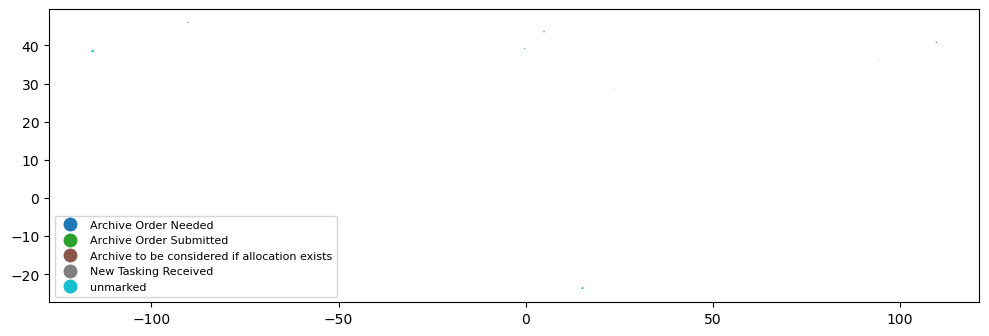

In [21]:
# Footprints of the tracked acquisitions in CSDA (one per acquisition and site); interactive if folium is installed
show = ['site_name', 'acq_num', 'sheet_platform', 'acquisition_id', 'status_TOA', 'status_SR', 'match']
footprints = acq_level[show + ['geometry']].assign(**{c: acq_level[c].astype(str) for c in show})
try:
    import folium
    display(footprints.explore(column='status_TOA', tooltip=show))
except ImportError:
    footprints.plot(column='status_TOA', legend=True, figsize=(12, 6), legend_kwds={'loc': 'lower left', 'fontsize': 8})

## 4b. Summary since September

For images **acquired on or after `SINCE`** at the tracked sites (CSDA STAC does not record when an item was added, so
"new" means acquired since then):

1. **New in CSDA STAC**: a fresh search at all tracked sites (the section 2 search uses the cache). Each image is marked
   if it fills a *New Tasking* request in the sheet (section 3b).
2. **Collected but not in CSDA STAC yet**: not known for Airbus (we have no view of Airbus's own catalog). What we do
   know is how many tasking requests in the sheet are still waiting.

In [22]:
res_since = multistac.search(sites, SINCE, END, PROVIDERS)   # no cache_dir: always a fresh search
sg = res_since.gdf.copy()
parsed = sg['id'].map(order_tracking.id_time)
sg['platform'] = [p for p, t in parsed]
sg['acq_time'] = [t for p, t in parsed]
sg['radiometry'] = (sg['airbus-optical:radiometric_processing']
                   .map({'REFLECTANCE': 'TOA', 'SURFACE_REFLECTANCE': 'SR', 'BASIC': 'basic'})
                   .fillna(sg['airbus-optical:radiometric_processing']))
new_since = (sg.dropna(subset=['acq_time'])
              .groupby(['site_name', 'platform', 'acquisition_id'], as_index=False)
              .agg(acq_time=('acq_time', 'first'), radiometry=('radiometry', lambda r: ', '.join(sorted(r.dropna().unique())))))
new_since = new_since[new_since.acq_time >= pd.Timestamp(SINCE, tz='UTC')].sort_values(['site_name', 'acq_time'])
tasked_ids = set(tracking.loc[tracking.match.eq('new tasking'), 'acquisition_id'])
new_since['fills_tasking_request'] = new_since.acquisition_id.isin(tasked_ids)

# Tasking requests in the sheet: one per TOA / SR cell of a 'New Tasking' slot
task_requests = tracking[tracking.status.isin([NEW_TASKING_STATUS, 'New Tasking Received'])]
by = lambda df: df.groupby('site_name')
since_summary = pd.DataFrame({
    'new_in_csda': by(new_since).size(),
    'with_SR': by(new_since[new_since.radiometry.str.contains('SR')]).size(),
    'fill_tasking_requests': by(new_since[new_since.fills_tasking_request]).size(),
    'tasking_requests': by(task_requests).size(),
    'requests_filled': by(task_requests[task_requests.status == 'New Tasking Received']).size(),
    'requests_waiting': by(task_requests[task_requests.status == NEW_TASKING_STATUS]).size(),
}).reindex(sorted(sites.site_name)).fillna(0).astype(int)
since_summary['platforms'] = by(new_since).platform.agg(lambda p: ', '.join(f"{k} {v}" for k, v in p.value_counts().items()))
since_summary['latest'] = by(new_since).acq_time.max().dt.strftime('%Y-%m-%d')
since_summary.loc['Total'] = since_summary.sum(numeric_only=True)
since_summary = since_summary.astype({c: int for c in since_summary.columns if c not in ('platforms', 'latest')})
print(res_since)
since_summary

searches: 100%|██████████| 8/8 [00:00<00:00, 17.60it/s]


SearchResult(58 rows, 58 unique items, 0 failed tasks)


,new_in_csda,with_SR,fill_tasking_requests,tasking_requests,requests_filled,requests_waiting,platforms,latest
site_name,,,,,,,,
Baotou,9,0,8,11,8,3,"PNEO3 3, PNEO4 2, PHR1B 2, PHR1A 2",2026-10-30
Gobabeb,0,0,0,0,0,0,NaN,NaN
Golmud,2,0,2,17,2,15,"PNEO4 1, PNEO3 1",2026-10-13
La Crau,0,0,0,0,0,0,NaN,NaN
PICS Libya-4,2,0,0,0,0,0,"PHR1B 1, PHR1A 1",2026-09-09
Railroad Valley,2,0,0,0,0,0,"PNEO3 1, PNEO4 1",2026-09-18
Valencia,1,1,1,24,2,22,PNEO3 1,2026-10-07
WLEF,7,5,7,41,12,29,"PNEO3 4, PHR1B 1, PHR1A 1, PNEO4 1",2026-10-24
Total,23,6,18,93,24,69,NaN,NaN


SearchResult(58 rows, 58 unique items, 0 failed tasks)


,new_in_csda,with_SR,fill_tasking_requests,tasking_requests,requests_filled,requests_waiting,platforms,latest
site_name,,,,,,,,
Baotou,9,0,8,11,8,3,"PNEO3 3, PNEO4 2, PHR1B 2, PHR1A 2",2026-10-30
Gobabeb,0,0,0,0,0,0,NaN,NaN
Golmud,2,0,2,17,2,15,"PNEO4 1, PNEO3 1",2026-10-13
La Crau,0,0,0,0,0,0,NaN,NaN
PICS Libya-4,2,0,0,0,0,0,"PHR1B 1, PHR1A 1",2026-09-09
Railroad Valley,2,0,0,0,0,0,"PNEO3 1, PNEO4 1",2026-09-18
Valencia,1,1,1,24,2,22,PNEO3 1,2026-10-07
WLEF,7,5,7,41,12,29,"PNEO3 4, PHR1B 1, PHR1A 1, PNEO4 1",2026-10-24
Total,23,6,18,93,24,69,NaN,NaN


In [23]:
from IPython.display import Markdown
today_ = pd.Timestamp.today().normalize()   # local date
d = lambda t: f"{pd.Timestamp(t):%-m/%-d/%y}"
per_site = lambda x: ', '.join(f"{k} {int(v)}" for k, v in x[x > 0].sort_values(ascending=False).items()) or 'none'
ss = since_summary.drop(index='Total')
n_new = len(new_since)
n_tasked = int(new_since.fills_tasking_request.sum())
quiet = ss[ss.new_in_csda == 0].index
n_req, n_filled, n_wait = len(task_requests), int((task_requests.status == 'New Tasking Received').sum()), int((task_requests.status == NEW_TASKING_STATUS).sum())
plat = ', '.join(f"{k} {v}" for k, v in new_since.platform.value_counts().items())

new_txt = (f"{n_new} Airbus images acquired since {d(SINCE)} are in the CSDA STAC, at {(ss.new_in_csda > 0).sum()} of "
           f"{len(ss)} sites ({per_site(ss.new_in_csda)}; by satellite: {plat}); {int(ss.with_SR.sum())} also have "
           f"surface reflectance. {n_tasked} of them fill tasking requests from the sheet.")
task_txt = (f"Tasking: {n_filled} of the {n_req} tasking requests in the tracking sheet (TOA and SR counted separately) "
            f"are filled; {n_wait} are still waiting ({per_site(ss.requests_waiting)}).")
unknown_txt = "Images Airbus has collected but not yet delivered cannot be counted: we have no view of Airbus's own catalog."
quiet_txt = f"Nothing new since {d(SINCE)} at {', '.join(quiet)}." if len(quiet) else ''
display(Markdown('\n'.join(f"- {t}" for t in [f"**As of {d(today_)}**", new_txt, task_txt, quiet_txt, unknown_txt] if t)))

receive_note = ' '.join(t for t in [
    f"Status {d(today_)} (images acquired since {d(SINCE)} at the {len(ss)} tracked sites).",
    f"New in CSDA STAC: {n_new} images at {(ss.new_in_csda > 0).sum()} sites ({per_site(ss.new_in_csda)}); "
    f"{int(ss.with_SR.sum())} with surface reflectance; {n_tasked} fill tasking requests.",
    f"Tasking requests: {n_filled} of {n_req} filled, {n_wait} still waiting.",
    f"Nothing new at {', '.join(quiet)}." if len(quiet) else '',
    "Collected but not yet delivered: unknown (no access to Airbus's catalog)."] if t)
print(receive_note)

- **As of 11/3/26**
- 23 Airbus images acquired since 9/1/26 are in the CSDA STAC, at 6 of 8 sites (Baotou 9, WLEF 7, Golmud 2, PICS Libya-4 2, Railroad Valley 2, Valencia 1; by satellite: PNEO3 10, PNEO4 5, PHR1B 4, PHR1A 4); 6 also have surface reflectance. 18 of them fill tasking requests from the sheet.
- Tasking: 24 of the 93 tasking requests in the tracking sheet (TOA and SR counted separately) are filled; 69 are still waiting (WLEF 29, Valencia 22, Golmud 15, Baotou 3).
- Nothing new since 9/1/26 at Gobabeb, La Crau.
- Images Airbus has collected but not yet delivered cannot be counted: we have no view of Airbus's own catalog.

Status 11/3/26 (images acquired since 9/1/26 at the 8 tracked sites). New in CSDA STAC: 23 images at 6 sites (Baotou 9, WLEF 7, Golmud 2, PICS Libya-4 2, Railroad Valley 2, Valencia 1); 6 with surface reflectance; 18 fill tasking requests. Tasking requests: 24 of 93 filled, 69 still waiting. Nothing new at Gobabeb, La Crau. Collected but not yet delivered: unknown (no access to Airbus's catalog).


## 5. Excel copy for colleagues

A copy of the `AirbusTracking` tab with the cells of acquisitions already in CSDA STAC filled green
(pale green = `'same pass?'` match, to check), and both added to the legend (G1, G2). A cell is recoloured
only if CSDA has that column's radiometry (TOA or SR). Values, other colours, borders and the
"CSDA has N scenes" headers are left as they were.

Slots filled with new tasking (section 3b) get the sheet's own *New Tasking Received* legend colour and the CSDA
acquisition ID (e.g. `PNEO3_202610061657285`; for PNeo TOA also the date, as in the archive rows). Reading the new
sheet with `order_tracking.read_airbus_tracking` gives these as `tracking_id` with their acquisition time.

In [24]:
from pathlib import Path
Path(OUT_DIR).mkdir(parents=True, exist_ok=True)
stamp = pd.Timestamp.today().strftime('%Y%m%d')
xlsx_out = f'{OUT_DIR}/{Path(TRACKING_XLSX).stem}_{TRACKING_SHEET}_CSDA_STAC_{stamp}.xlsx'
recoloured = order_tracking.write_csda_status(TRACKING_XLSX, xlsx_out, tracking, TRACKING_SHEET)
print(xlsx_out)
recoloured.groupby(['color', 'status']).size()

/explore/nobackup/people/pmontesa/multistac/airbus_order_tracking/OnRamp2_OrderTracking_August2026_AirbusTracking_CSDA_STAC_20261103.xlsx


color                                                  status                                       
In CSDA STAC (as of 2026-11-03)                        Archive Order Needed                              1
                                                       Archive Order Submitted                          64
                                                       Archive to be considered if allocation exists    14
Likely in CSDA STAC (acquisition time differs; check)  Archive Order Submitted                           6
                                                       unmarked                                          2
New Tasking Received                                   New Tasking Received                             24
dtype: int64

## Save

In [25]:
# from pathlib import Path
# Path(OUT_DIR).mkdir(parents=True, exist_ok=True)
# stamp = pd.Timestamp.today().strftime('%Y%m%d')
# in_csda_gdf.assign(datetime=in_csda_gdf.datetime.astype(str)).to_file(f'{OUT_DIR}/airbus_tracking_in_csda_{stamp}.gpkg', driver='GPKG')
# tracking.to_csv(f'{OUT_DIR}/airbus_tracking_status_{stamp}.csv', index=False)

## 6. Download the new data from CSDA

Downloads the CSDA products of the tracked acquisitions (`in_csda_gdf`) into `DOWNLOAD_DIR/<item id>/`, the same way as
`csda_stac_download.ipynb`: Earthdata login from `credentials.ini` → `CsdaClient` → `csdalib_download.download_all_assets`
in a thread pool.

`in_csda_gdf` includes the new tasking products (section 3b).

*New* = not already downloaded. A product is skipped if a folder `<dir>/<item id>/` holds all of its assets in any of
`ALREADY_HAVE_DIRS` (`Data/Airbus` and `DOWNLOAD_DIR`), **or** the same product is in the local footprints
(`LOCAL_FOOTPRINTS`, from `footprint_CSDA_eval_all_data.ipynb`): same platform, P / MS, radiometry and acquisition
time within `MATCH_SECONDS`. The footprint check catches ad hoc downloads filed under other folder names; rerun the
footprint notebook after a download so it stays current. Files already in `DOWNLOAD_DIR` are kept
(`overwrite=False`), so re-running resumes an interrupted download.

Runs in the **ILAB DEV kernel** (where `csda_client` is installed).

In [26]:
from pathlib import Path

DOWNLOAD_DIR = Path('/explore/nobackup/projects/CSDA_eval/Data/Airbus/augmentation')
ALREADY_HAVE_DIRS = [Path('/explore/nobackup/projects/CSDA_eval/Data/Airbus'), DOWNLOAD_DIR]   # <dir>/<item id>/ = already downloaded
LOCAL_FOOTPRINTS = '/explore/nobackup/projects/CSDA_eval/footprints/footprints_CSDA_eval_ACQUISITIONS_latest.csv'   # one row per local product
INCLUDE_CHECK = True     # also download match == 'same pass?' acquisitions (see section 3)
DOWNLOAD_ALL = True      # True: every asset (images + sidecars). False: metadata only + product info table
DO_DOWNLOAD = True      # set True to download
MAX_WORKERS = 8
CREDENTIALS_FILE = '/home/pmontesa/code/credentials.ini'

In [27]:
import pystac

want = in_csda_gdf if INCLUDE_CHECK else in_csda_gdf[in_csda_gdf.match.isin(['id time', 'new tasking'])]
item_dicts = {it['id']: it for it in res.items}
def already_have(item_id):   # every asset of the item on disk in one of the dirs (some files = interrupted, resumed)
    n_assets = len(item_dicts[item_id]['assets'])
    return any((d / item_id).is_dir() and len([f for f in (d / item_id).iterdir() if f.stat().st_size > 0]) >= n_assets
               for d in ALREADY_HAVE_DIRS)

# The same product downloaded under another folder name (ad hoc downloads): same platform, P / MS, radiometry
# and acquisition time in the local footprints
local = pd.read_csv(LOCAL_FOOTPRINTS, usecols=['affiliation', 'sensor', 'acquisition_datetime', 'image_type',
                                               'radiometric_type', 'metadata_path'])
local = local[local.affiliation.eq('Airbus')].copy()
# Time as in the CSDA ID: from the metadata file name (DIM_PHR1A_MS_202503311054361_ORT_...); the footprint time is
# the first located time (PHR Top Center), up to several seconds later
name_time = local.metadata_path.str.extract(r'_(\d{14})(\d)_[^/]*$')
local['local_time'] = (pd.to_datetime(name_time[0], format='%Y%m%d%H%M%S', utc=True, errors='coerce')
                       + pd.to_timedelta(name_time[1].astype(float) / 10, unit='s')
                       ).fillna(pd.to_datetime(local.acquisition_datetime.map(pd.Timestamp), utc=True))   # mixed ISO formats
local['image_type'] = local.image_type.mask(local.metadata_path.str.contains('_PMS_', na=False), 'PMS')   # pansharpened, not MS
products = want.drop_duplicates('id').assign(
    sensor=lambda d: d.id.map(lambda i: order_tracking.id_time(i)[0]),
    t=lambda d: d.id.map(lambda i: order_tracking.id_time(i)[1]),
    image_type=lambda d: d.spectral_mode.map({'pan': 'P', 'ms': 'MS'}),
    radiometric_type=lambda d: d.radiometry.map({'TOA': 'REFLECTANCE', 'SR': 'SURFACE_REFLECTANCE', 'basic': 'BASIC'}))
on_disk = pd.merge_asof(
    products.dropna(subset=['image_type', 'radiometric_type']).sort_values('t')[['id', 'sensor', 't', 'image_type', 'radiometric_type']],
    local.sort_values('local_time')[['sensor', 'local_time', 'image_type', 'radiometric_type', 'metadata_path']],
    left_on='t', right_on='local_time', by=['sensor', 'image_type', 'radiometric_type'],
    tolerance=pd.Timedelta(seconds=MATCH_SECONDS), direction='nearest')
local_copy = on_disk.dropna(subset=['metadata_path']).set_index('id').metadata_path

have = {i for i in want.id.unique() if already_have(i) or i in local_copy.index}
print(f"Already downloaded: {sum(already_have(i) for i in want.id.unique())} by item folder, "
      f"{len(local_copy)} in the local footprints")
new_ids = [i for i in want.id.unique() if i not in have]
STAC_ITEMS_DOWNLOAD = [pystac.Item.from_dict(item_dicts[i]) for i in new_ids]

gb = {i: sum(a.get('file:size') or 0 for a in item_dicts[i]['assets'].values()) / 1e9 for i in new_ids}
print(f"{want.id.nunique()} products of tracked acquisitions in CSDA: {len(have)} already downloaded, "
      f"{len(STAC_ITEMS_DOWNLOAD)} new ({sum(gb.values()):.1f} GB, all assets)")

new = want[want.id.isin(new_ids)].drop_duplicates('id').assign(GB=lambda d: d.id.map(gb))
new.groupby(['site_name', 'sheet_platform', 'radiometry']).agg(products=('id', 'size'), GB=('GB', 'sum')).round(2)

Already downloaded: 218 by item folder, 218 in the local footprints
222 products of tracked acquisitions in CSDA: 218 already downloaded, 4 new (2.6 GB, all assets)


products    GB
site_name sheet_platform radiometry                
Baotou    PHR1A          TOA                2  1.28
          PHR1B          TOA                2  1.28

In [28]:
import configparser
import tabulate
from httpx import BasicAuth
from csda_client import CsdaClient
import csdalib_download
importlib.reload(csdalib_download)

def load_earthdata_creds(path=CREDENTIALS_FILE):
    config = configparser.ConfigParser()
    config.read(Path(path).expanduser())
    return config['EarthData']['username'], config['EarthData']['password']

username, password = load_earthdata_creds()
client = CsdaClient.open(BasicAuth(username=username, password=password))
print('Auth:', client.verify())
try:   # csda_client 0.1.0's Profile model fails on the current API response (missing 'nda_signed')
    profile = client.profile(username)
    rows = [[vendor.vendor, vendor.quota, vendor.quota_unit] for vendor in profile.vendors]
    print(tabulate.tabulate(rows, headers=['Vendor', 'Quota', 'Quota unit'], tablefmt='simple'))
except Exception as e:
    print('Quota table unavailable:', str(e).splitlines()[0])

Auth: Hello montesano, you have a valid token!
Quota table unavailable: 1 validation error for Profile


In [29]:
from concurrent.futures import ThreadPoolExecutor, as_completed
import os

records = []
if not DO_DOWNLOAD:
    print(f'DO_DOWNLOAD = False: would download {len(STAC_ITEMS_DOWNLOAD)} products to {DOWNLOAD_DIR}')
else:
    # Pre-create the item folders before the threads write to them
    for item in STAC_ITEMS_DOWNLOAD:
        os.makedirs(DOWNLOAD_DIR / item.id, exist_ok=True)
    # Which tracked acquisition each product belongs to, next to the data
    want.drop(columns='geometry').to_csv(DOWNLOAD_DIR / 'onramp2_tracked_products.csv', index=False)

    with ThreadPoolExecutor(max_workers=MAX_WORKERS) as pool:
        if DOWNLOAD_ALL:
            futures = {pool.submit(csdalib_download.download_all_assets, item, client,
                                   DOWNLOAD_DIR / item.id, overwrite=False): item
                       for item in STAC_ITEMS_DOWNLOAD}
        else:
            futures = {pool.submit(csdalib_download._process_one_item, item, client,
                                   DOWNLOAD_DIR / item.id): item
                       for item in STAC_ITEMS_DOWNLOAD}
        for future in as_completed(futures):
            item = futures[future]
            try:
                out = future.result()
                if out is not None:
                    records.append({'item_id': item.id, **out} if DOWNLOAD_ALL else out)
                print(f'Successfully processed: {item.id}')
            except Exception as e:
                print(f'Error on {item.id}: {e}')

products_df = pd.DataFrame(records)
products_df.head()

  ✓ icon                  → ICON_PHR1A_MS_202610300333504_ORT_7932090101-2.JPG
  ✓ icon                  → ICON_PHR1A_P_202610300333504_ORT_7932090101-1.JPG
  ✓ icon                  → ICON_PHR1B_MS_202610290340226_ORT_7931621101-2.JPG
  ✓ icon                  → ICON_PHR1B_P_202610290340226_ORT_7931621101-1.JPG
  ✓ metadata              → DIM_PHR1A_P_202610300333504_ORT_7932090101-1.XML
  ✓ metadata              → DIM_PHR1B_MS_202610290340226_ORT_7931621101-2.XML
  ✓ metadata              → DIM_PHR1A_MS_202610300333504_ORT_7932090101-2.XML
  ✓ metadata              → DIM_PHR1B_P_202610290340226_ORT_7931621101-1.XML
  ✓ thumbnail             → PREVIEW_PHR1A_P_202610300333504_ORT_7932090101-1.JPG
  ✓ thumbnail             → PREVIEW_PHR1B_MS_202610290340226_ORT_7931621101-2.JPG
  ✓ thumbnail             → PREVIEW_PHR1A_MS_202610300333504_ORT_7932090101-2.JPG
  ✓ thumbnail             → PREVIEW_PHR1B_P_202610290340226_ORT_7931621101-1.JPG
  ✓ auxiliary_0           → PROCESSING_PHR1A_P_202

,item_id,icon,metadata,thumbnail,auxiliary_0,auxiliary_1,auxiliary_2,auxiliary_3,visual-r1c1,snow-quality-mask,cloud-quality-mask,area-of-interest-mask,detector-quality-mask,technical-quality-mask,saturation-quality-mask,visibility-quality-mask
0,PHR1A_202610300333504_MS_ORT_RFL,/explore/nobackup/projects/CSDA_eval/Data/Airb...,/explore/nobackup/projects/CSDA_eval/Data/Airb...,/explore/nobackup/projects/CSDA_eval/Data/Airb...,/explore/nobackup/projects/CSDA_eval/Data/Airb...,/explore/nobackup/projects/CSDA_eval/Data/Airb...,/explore/nobackup/projects/CSDA_eval/Data/Airb...,/explore/nobackup/projects/CSDA_eval/Data/Airb...,/explore/nobackup/projects/CSDA_eval/Data/Airb...,/explore/nobackup/projects/CSDA_eval/Data/Airb...,/explore/nobackup/projects/CSDA_eval/Data/Airb...,/explore/nobackup/projects/CSDA_eval/Data/Airb...,/explore/nobackup/projects/CSDA_eval/Data/Airb...,/explore/nobackup/projects/CSDA_eval/Data/Airb...,/explore/nobackup/projects/CSDA_eval/Data/Airb...,/explore/nobackup/projects/CSDA_eval/Data/Airb...
1,PHR1B_202610290340226_MS_ORT_RFL,/explore/nobackup/projects/CSDA_eval/Data/Airb...,/explore/nobackup/projects/CSDA_eval/Data/Airb...,/explore/nobackup/projects/CSDA_eval/Data/Airb...,/explore/nobackup/projects/CSDA_eval/Data/Airb...,/explore/nobackup/projects/CSDA_eval/Data/Airb...,/explore/nobackup/projects/CSDA_eval/Data/Airb...,/explore/nobackup/projects/CSDA_eval/Data/Airb...,/explore/nobackup/projects/CSDA_eval/Data/Airb...,/explore/nobackup/projects/CSDA_eval/Data/Airb...,/explore/nobackup/projects/CSDA_eval/Data/Airb...,/explore/nobackup/projects/CSDA_eval/Data/Airb...,/explore/nobackup/projects/CSDA_eval/Data/Airb...,/explore/nobackup/projects/CSDA_eval/Data/Airb...,/explore/nobackup/projects/CSDA_eval/Data/Airb...,/explore/nobackup/projects/CSDA_eval/Data/Airb...
2,PHR1B_202610290340226_P_ORT_RFL,/explore/nobackup/projects/CSDA_eval/Data/Airb...,/explore/nobackup/projects/CSDA_eval/Data/Airb...,/explore/nobackup/projects/CSDA_eval/Data/Airb...,/explore/nobackup/projects/CSDA_eval/Data/Airb...,/explore/nobackup/projects/CSDA_eval/Data/Airb...,/explore/nobackup/projects/CSDA_eval/Data/Airb...,/explore/nobackup/projects/CSDA_eval/Data/Airb...,/explore/nobackup/projects/CSDA_eval/Data/Airb...,/explore/nobackup/projects/CSDA_eval/Data/Airb...,/explore/nobackup/projects/CSDA_eval/Data/Airb...,/explore/nobackup/projects/CSDA_eval/Data/Airb...,/explore/nobackup/projects/CSDA_eval/Data/Airb...,/explore/nobackup/projects/CSDA_eval/Data/Airb...,/explore/nobackup/projects/CSDA_eval/Data/Airb...,/explore/nobackup/projects/CSDA_eval/Data/Airb...
3,PHR1A_202610300333504_P_ORT_RFL,/explore/nobackup/projects/CSDA_eval/Data/Airb...,/explore/nobackup/projects/CSDA_eval/Data/Airb...,/explore/nobackup/projects/CSDA_eval/Data/Airb...,/explore/nobackup/projects/CSDA_eval/Data/Airb...,/explore/nobackup/projects/CSDA_eval/Data/Airb...,/explore/nobackup/projects/CSDA_eval/Data/Airb...,/explore/nobackup/projects/CSDA_eval/Data/Airb...,/explore/nobackup/projects/CSDA_eval/Data/Airb...,/explore/nobackup/projects/CSDA_eval/Data/Airb...,/explore/nobackup/projects/CSDA_eval/Data/Airb...,/explore/nobackup/projects/CSDA_eval/Data/Airb...,/explore/nobackup/projects/CSDA_eval/Data/Airb...,/explore/nobackup/projects/CSDA_eval/Data/Airb...,/explore/nobackup/projects/CSDA_eval/Data/Airb...,/explore/nobackup/projects/CSDA_eval/Data/Airb...


In [30]:
# Check: assets on disk vs assets in the STAC item, per product
check = pd.DataFrame([{'id': i,
                       'assets': len(item_dicts[i]['assets']),
                       'files_on_disk': len([f for f in (DOWNLOAD_DIR / i).glob('*') if f.stat().st_size > 0])
                                        if (DOWNLOAD_DIR / i).exists() else 0}
                      for i in new_ids])
check['complete'] = check.files_on_disk >= check.assets
print(f"{check.complete.sum()} of {len(check)} products complete in {DOWNLOAD_DIR}")
check[~check.complete]

4 of 4 products complete in /explore/nobackup/projects/CSDA_eval/Data/Airbus/augmentation


,id,assets,files_on_disk,complete
